Домашнее задание по теме 6

$\textbf{Часть 1}$

а) постройте матричную диаграмму рассеяния и определите нижнюю границу для числа кластеров K; 

In [48]:
import pandas as pd
import seaborn as sb
import numpy as np

d = pd.read_table('data/Simpl.txt',  sep='\t')
d.shape

(25, 4)

n = 25, m = 4

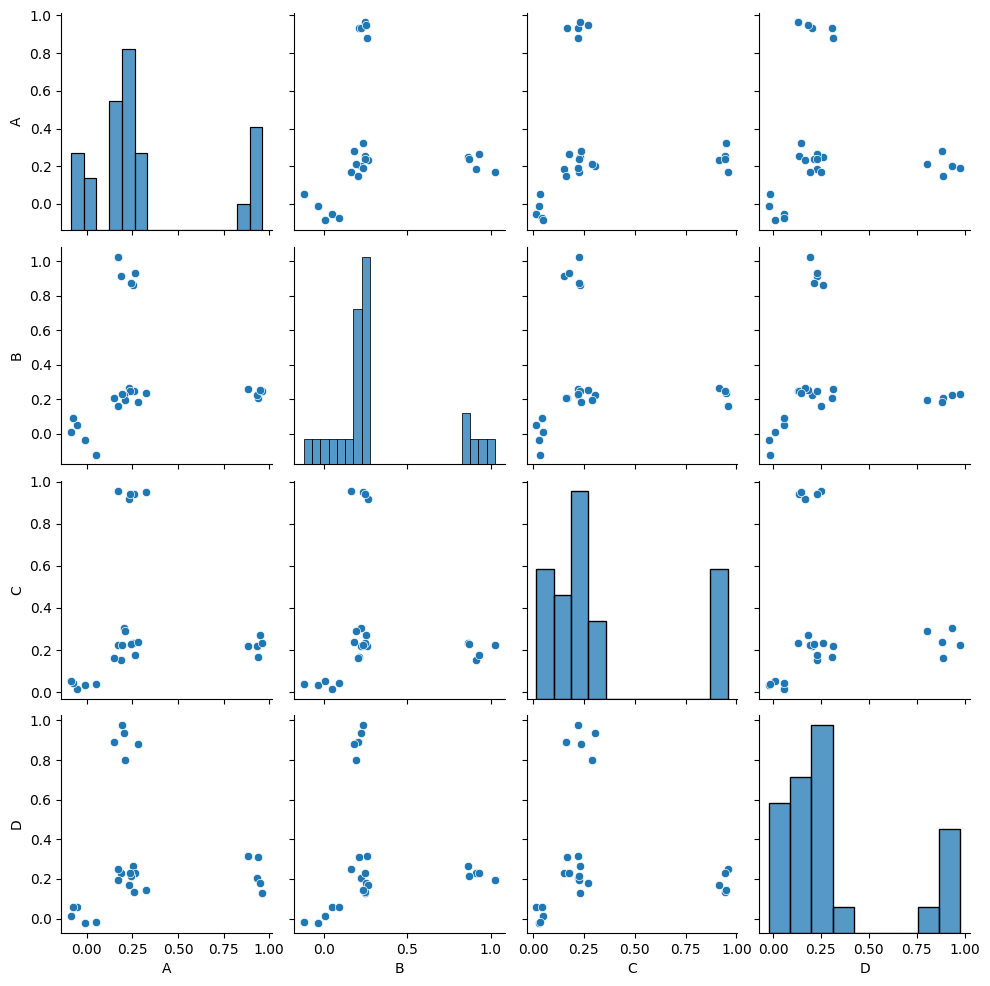

In [49]:
for col in d:
    d[col] = d[col].str.replace(',', '.').astype(float)
sb.pairplot(d)

Судя по диаграмме кластеров будет хотя бы 4

б) выполните кластеризацию методом K-средних;

In [50]:
np.random.seed(10**7)
from sklearn.cluster import KMeans

k = 4
r = KMeans(n_clusters=k, init='random', n_init=20).fit(d)

в) постройте матричную диаграмму рассеяния с раскраской точек в цвета кластеров и 
проанализируйте её (имеются ли наложения проекций кластеров или распадения кластера на части), 
сделайте вывод о том, правильно ли было выбрано число кластеров. 

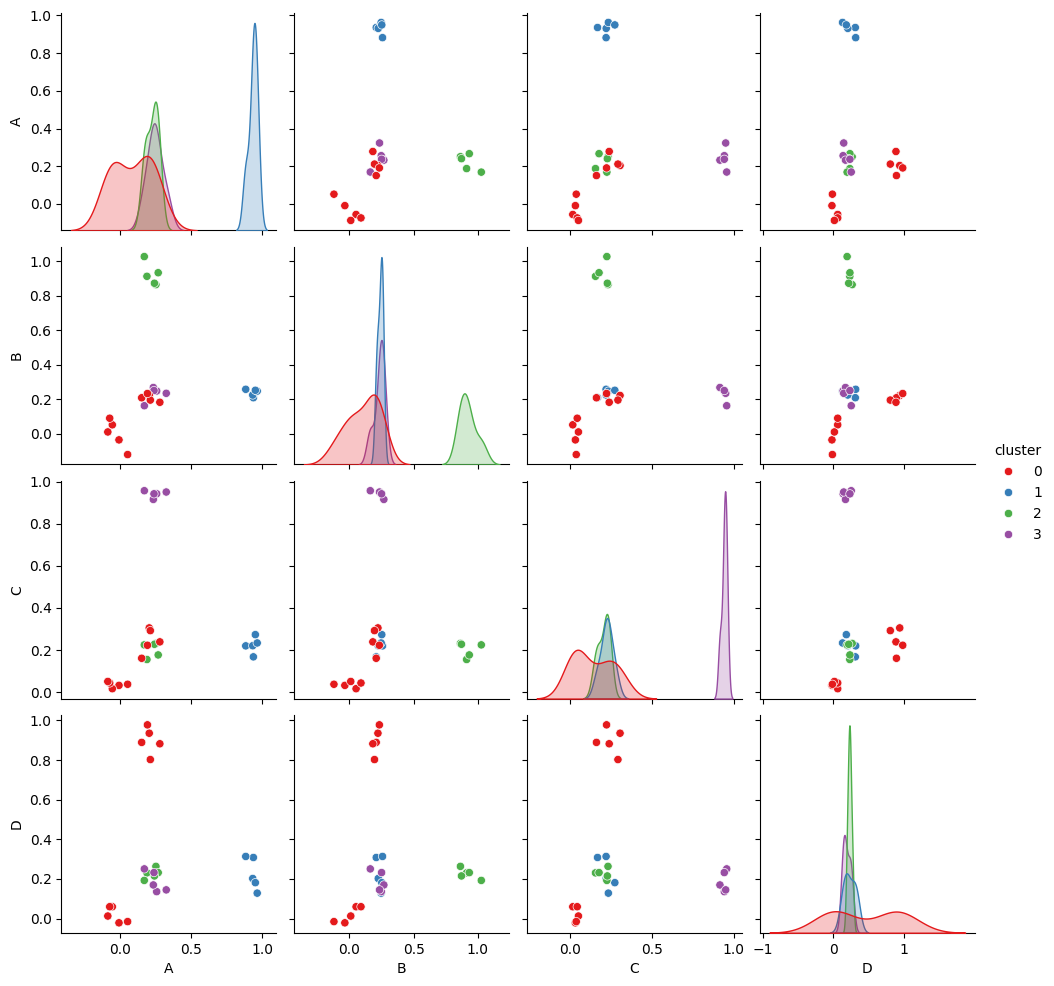

In [51]:
t = d.copy()
c = 'cluster'
t[c] = r.labels_
sb.pairplot(t, hue=c, palette='Set1')

Имеются наложения цветов. Нужно брать другое количество кластеров

$\textbf{Часть 2}$

а) получите матрицу попарных расстояний между эталонами (запишите её) и выясните, имеются ли 
расстояния, которые заметно меньше других;

In [55]:
from scipy.spatial import distance
import numpy as np

cent = r.cluster_centers_
dist_matrix = distance.cdist(cent, cent, metric='euclidean')
dist_matrix

array([[0.        , 0.89157291, 0.86363638, 0.87133126],
       [0.89157291, 0.        , 0.98581137, 0.99681759],
       [0.86363638, 0.98581137, 0.        , 1.01190886],
       [0.87133126, 0.99681759, 1.01190886, 0.        ]])

Заметно меньших расстояний не наблюдается

б) постройте профили кластеров и ответьте, имеются ли среди ломаных похожие; 

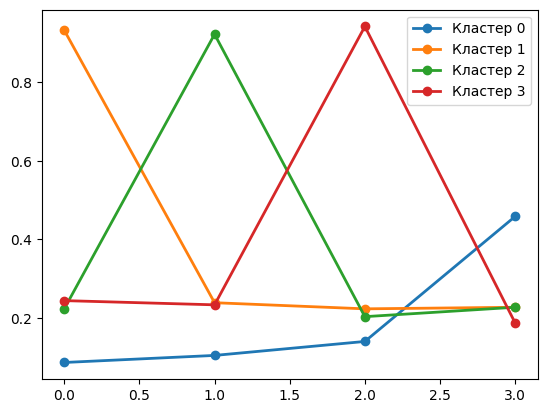

In [57]:
import matplotlib.pyplot as plt

plt.plot(cent.T, marker='o', linewidth=2)
plt.legend([f'Кластер {i}' for i in range(cent.shape[0])])
plt.show()

Вроде бы похожих нету

в) укажите долю общей инерции, приходящуюся на внутрикластерную инерцию; 

In [59]:
import numpy as np

v = d.mean(0).values
print(f"Общий центр масс: {v}")
total_inertia = 0
for i in range(d.shape[0]):
    total_inertia += np.sum((d.values[i] - v) ** 2)
share = r.inertia_ / total_inertia
print(f"Доля внутрикластерной инерции: {share}")

Общий центр масс: [0.31416914 0.32029349 0.32934293 0.3112534 ]
Доля внутрикластерной инерции: 0.24618300350759287


г) выполните пункты а), б), в) для числа кластеров K = 4, 5, 6; определите истинное число кластеров и 
опишите кластеры на основе их профилей. 

k=5:

[[0.         1.03486898 0.98581137 0.99681759 0.98846419]
 [1.03486898 0.         0.99455264 0.99099968 0.95729909]
 [0.98581137 0.99455264 0.         1.01190886 0.98020988]
 [0.99681759 0.99099968 1.01190886 0.         0.99727966]
 [0.98846419 0.95729909 0.98020988 0.99727966 0.        ]]


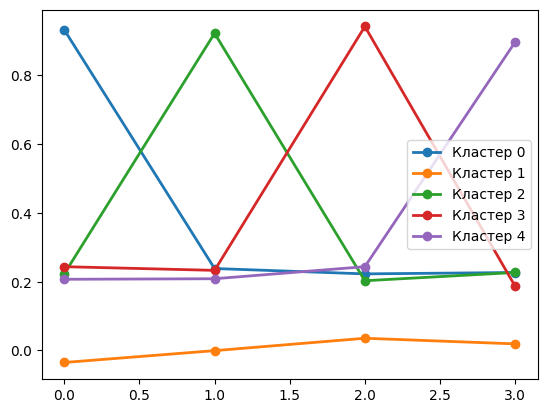

Общий центр масс: [0.31416914 0.32029349 0.32934293 0.3112534 ]
Доля внутрикластерной инерции: 0.01862428781386762


In [62]:
k = 5
r = KMeans(n_clusters=k, init='random', n_init=20).fit(d)
cent = r.cluster_centers_
dist_matrix = distance.cdist(cent, cent, metric='euclidean')
print(dist_matrix)
plt.plot(cent.T, marker='o', linewidth=2)
plt.legend([f'Кластер {i}' for i in range(cent.shape[0])])
plt.show()
v = d.mean(0).values
print(f"Общий центр масс: {v}")
total_inertia = 0
for i in range(d.shape[0]):
    total_inertia += np.sum((d.values[i] - v) ** 2)
share = r.inertia_ / total_inertia
print(f"Доля внутрикластерной инерции: {share}")

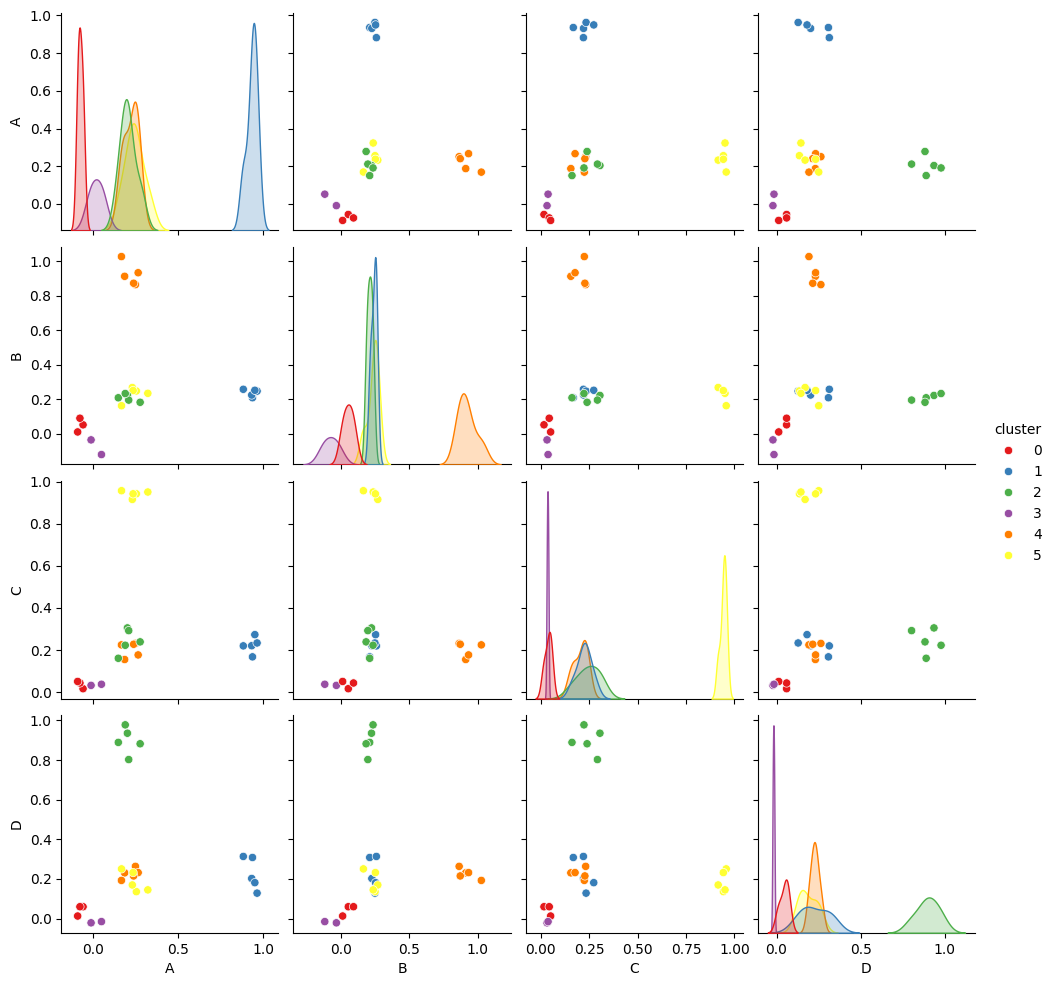

In [64]:
t = d.copy()
c = 'cluster'
t[c] = r.labels_
sb.pairplot(t, hue=c, palette='Set1')

k=6

[[0.         1.05499701 0.9346102  0.1712485  0.952588   0.98679196]
 [1.05499701 0.         0.98846419 1.0126461  0.98581137 0.99681759]
 [0.9346102  0.98846419 0.         0.99920226 0.98020988 0.99727966]
 [0.1712485  1.0126461  0.99920226 0.         1.06268396 1.00606113]
 [0.952588   0.98581137 0.98020988 1.06268396 0.         1.01190886]
 [0.98679196 0.99681759 0.99727966 1.00606113 1.01190886 0.        ]]


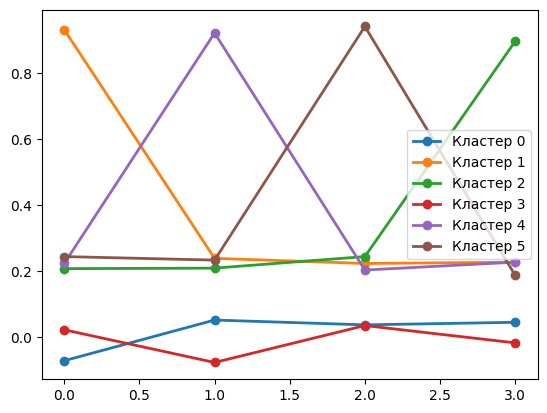

Общий центр масс: [0.31416914 0.32029349 0.32934293 0.3112534 ]
Доля внутрикластерной инерции: 0.015128919266358565


In [63]:
k = 6
r = KMeans(n_clusters=k, init='random', n_init=20).fit(d)
cent = r.cluster_centers_
dist_matrix = distance.cdist(cent, cent, metric='euclidean')
print(dist_matrix)
plt.plot(cent.T, marker='o', linewidth=2)
plt.legend([f'Кластер {i}' for i in range(cent.shape[0])])
plt.show()
v = d.mean(0).values
print(f"Общий центр масс: {v}")
total_inertia = 0
for i in range(d.shape[0]):
    total_inertia += np.sum((d.values[i] - v) ** 2)
share = r.inertia_ / total_inertia
print(f"Доля внутрикластерной инерции: {share}")

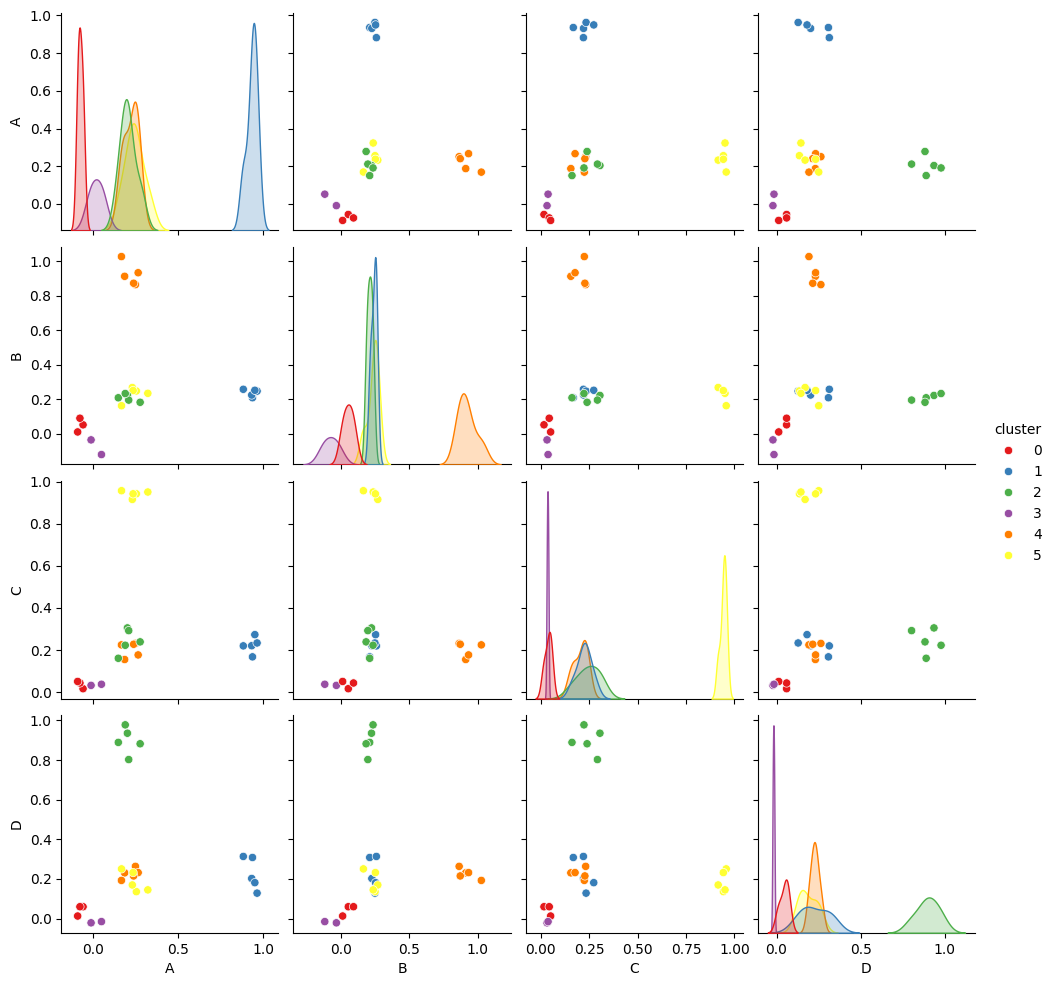

In [65]:
t = d.copy()
c = 'cluster'
t[c] = r.labels_
sb.pairplot(t, hue=c, palette='Set1')

Вывод: на мой взгляд, k=5 выглядит оптимально, т.к. при k=6 ломанные синего и красного кластеров сильно похожи, а при k=4 большая внутрикластерная инерция.